# 26 — Modern-Generator Replication of the Self-History Intervention

## Goal

The original causal validation used Qwen2.5-1.5B-Instruct and SmolLM2. The
remaining generator-side question is whether the same completed-text trace
appears for larger, contemporary, independent instruction-model families.

This notebook generates a new matched intervention dataset using:

- `meta-llama/Llama-3.2-3B-Instruct`
- `tiiuae/Falcon3-3B-Instruct`

on the **same 60 RAID source prompts** used by the frozen Qwen2.5 confirmatory
intervention.

The old SmolLM2 generator is not part of the primary modern-generator claim. It
remains a historical supporting replication.

## Intervention

For each RAID task prompt \(p\), compare

\[
\text{full:}\qquad p \oplus y_{<t}
\]

against

\[
\text{cap32:}\qquad p \oplus y_{t-32:t-1}.
\]

Thus the task prompt is always preserved, while generated self-history is capped
at 32 **generator tokens**. This matches the manuscript's existing intervention
description: the retained generated suffix is re-presented after the intact task
prompt.

Generation is greedy in both conditions. The only intended treatment difference
is access to earlier generated self-history.

## Frozen evaluation

Primary observation model:

- `Qwen/Qwen3-0.6B-Base`

Secondary scorer-scale replication:

- `Qwen/Qwen3-1.7B-Base`

For each completed generation,

\[
U(k)=L_8-L_k,\qquad k\in\{32,128,256\},
\]

using the paper's frozen 384-scorer-token prefix and eight deterministic target
positions.

The paired treatment effect is

\[
\Delta U(k)=U_{\mathrm{cap32}}(k)-U_{\mathrm{full}}(k).
\]

We predeclare

\[
\Delta U_{\mathrm{long}}
=
\frac{\Delta U(128)+\Delta U(256)}{2}
\]

and

\[
S_{\mathrm{long-short}}
=
\Delta U_{\mathrm{long}}-\Delta U(32).
\]

The predicted pattern is

\[
\Delta U_{\mathrm{long}}<0
\quad\text{and}\quad
S_{\mathrm{long-short}}<0.
\]

A modern generator counts as a **primary replication** only if both bootstrap
95% intervals are entirely below zero under the frozen Qwen3-0.6B scorer.
Qwen3-1.7B is a secondary observation-model robustness check.


In [1]:
from huggingface_hub import notebook_login

notebook_login()

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from transformers import AutoTokenizer, AutoConfig

checkpoint = "meta-llama/Llama-3.2-3B-Instruct"

tok = AutoTokenizer.from_pretrained(
    checkpoint,
    use_fast=True,
)

cfg = AutoConfig.from_pretrained(checkpoint)

print("✓ Llama access works")
print("model type:", cfg.model_type)

✓ Llama access works
model type: llama


In [3]:
from pathlib import Path
import gc
import inspect
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

GENERATOR = {
    "Llama3.2-3B": "meta-llama/Llama-3.2-3B-Instruct",
    "Falcon3-3B": "tiiuae/Falcon3-3B-Instruct",
}

# GENERATOR = {
#     "Falcon3-3B": "tiiuae/Falcon3-3B-Instruct",
# }

SCORERS = {
    "Qwen3-0.6B": "Qwen/Qwen3-0.6B-Base",
    "Qwen3-1.7B": "Qwen/Qwen3-1.7B-Base",
}

HISTORY_CAP = 32
MAX_NEW_TOKENS = 480

SCORER_PREFIX_LEN = 384
CONTEXTS = [8, 32, 128, 256]
N_TARGETS = 8
TARGET_POSITIONS = np.unique(
    np.linspace(
        max(CONTEXTS),
        SCORER_PREFIX_LEN - 1,
        N_TARGETS,
        dtype=int,
    )
)

N_BOOT = 10_000
BOOT_SEED = 20260901

# Set only for debugging. Leave None for the actual experiment.
DEBUG_N = None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True

print("ROOT:", ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("device:", DEVICE)
print("dtype:", DTYPE)
print("target positions:", TARGET_POSITIONS)


ROOT: ..
PROJECT_ROOT: /home/user/Downloads/TemporalContextResearch
device: cuda
dtype: torch.float16
target positions: [256 274 292 310 328 346 364 383]


## 1. Recover the exact 60 source IDs from the original Qwen intervention


In [4]:
Q_DIR_CANDIDATES = [
    DATA / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_confirmatory",
]

Q_DIR = next(
    (p for p in Q_DIR_CANDIDATES if (p / "confirmatory_pairs.parquet").exists()),
    None,
)
assert Q_DIR is not None, (
    "Could not locate confirmatory_pairs.parquet. Checked:\n"
    + "\n".join(map(str, Q_DIR_CANDIDATES))
)

frozen_pairs = pd.read_parquet(Q_DIR / "confirmatory_pairs.parquet")
SOURCE_IDS = list(dict.fromkeys(frozen_pairs["source_id"].astype(str)))

assert len(SOURCE_IDS) == 60, f"Expected 60 frozen source IDs, got {len(SOURCE_IDS)}"

if DEBUG_N is not None:
    SOURCE_IDS = SOURCE_IDS[: int(DEBUG_N)]

print("Q_DIR:", Q_DIR)
print("source IDs:", len(SOURCE_IDS))
print("first 5:", SOURCE_IDS[:5])


Q_DIR: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory
source IDs: 60
first 5: ['1b2e45a9-88d5-4983-b735-dc521aa6c1dc', '3b8f603e-fce8-4fb1-b5ef-49015b1e9677', '4e7eee59-305e-4449-a385-516cd0eef09f', 'fc13052b-289e-4247-9444-996c4d420c5d', '914cab2e-a79d-458d-b2c0-b173775dd0dd']


## 2. Recover the original RAID task prompts

RAID stores a `prompt` field keyed by `source_id`. We search local project
parquet files for those exact IDs and require one unique prompt per source.

If no local table contains `source_id` + `prompt`, set
`PROMPT_TABLE_OVERRIDE` to a local RAID parquet containing those columns and
rerun. The notebook deliberately refuses to infer prompts from generated text.


In [5]:
# ============================================================
# Recover canonical RAID instruction prompts for the frozen 60 IDs.
#
# RAID stores different prompt formulations for base/completion
# models vs chat/instruction models. Notebook 26 uses instruction
# generators, so we recover the canonical prompt used by the
# released chat-model conditions.
# ============================================================

RAID_PROMPT_SOURCE = (
    PROJECT_ROOT
    / "results"
    / "raid_pilot"
    / "raid_pilot_wavedetect.parquet"
)

assert RAID_PROMPT_SOURCE.exists(), RAID_PROMPT_SOURCE

cols = [
    "source_id",
    "prompt",
    "title",
    "domain",
    "model",
    "decoding",
    "repetition_penalty",
    "attack",
]

raid = pd.read_parquet(
    RAID_PROMPT_SOURCE,
    columns=cols,
).copy()

raid["source_id"] = raid["source_id"].astype(str)

# Only the exact frozen source population.
raid = raid[
    raid["source_id"].isin(set(SOURCE_IDS))
].copy()

# Clean RAID generation condition.
raid = raid[
    (raid["decoding"].astype(str).str.lower() == "greedy")
    & (raid["repetition_penalty"].astype(str).str.lower() == "no")
    & (raid["attack"].astype(str).str.lower() == "none")
].copy()

# ------------------------------------------------------------
# RAID's chat/instruction generators use the task-instruction
# prompt formulation. These are the appropriate source rows for
# our new Instruct generators.
# ------------------------------------------------------------
INSTRUCTION_MODELS = {
    "chatgpt",
    "gpt4",
    "llama-chat",
}

inst = raid[
    raid["model"].astype(str).str.lower().isin(INSTRUCTION_MODELS)
].copy()

inst = inst[inst["prompt"].notna()].copy()
inst["prompt"] = inst["prompt"].astype(str).str.strip()

print("Instruction-model rows:", len(inst))
print("Source IDs represented:", inst["source_id"].nunique())


# ============================================================
# Verify that all instruction-model rows agree on one prompt
# per source_id.
# ============================================================

prompt_sets = (
    inst.groupby("source_id")["prompt"]
    .agg(lambda s: list(pd.unique(s)))
)

bad = prompt_sets[prompt_sets.map(len) != 1]

if len(bad):
    print("\nInstruction-model prompt disagreements:")
    display(bad)

    raise RuntimeError(
        "RAID instruction-model conditions disagree on the task prompt "
        "for at least one frozen source ID."
    )

missing = set(SOURCE_IDS) - set(prompt_sets.index)

if missing:
    print("Missing instruction prompts for:")
    for sid in sorted(missing):
        print(" ", sid)

    raise RuntimeError(
        f"Only recovered {len(prompt_sets)}/{len(SOURCE_IDS)} "
        "instruction prompts."
    )


# ============================================================
# Construct frozen prompt table in original source order.
# ============================================================

prompt_map = {
    sid: vals[0]
    for sid, vals in prompt_sets.items()
}

# Also recover title/domain for audit.
meta = (
    inst[
        ["source_id", "title", "domain"]
    ]
    .drop_duplicates()
)

meta_counts = meta.groupby("source_id").size()

if (meta_counts != 1).any():
    display(
        meta[
            meta["source_id"].isin(
                meta_counts[meta_counts != 1].index
            )
        ]
    )
    raise RuntimeError(
        "Expected exactly one title/domain pair per source_id."
    )

meta = meta.set_index("source_id")

prompts = pd.DataFrame({
    "source_id": SOURCE_IDS,
    "prompt": [
        prompt_map[sid]
        for sid in SOURCE_IDS
    ],
    "title": [
        meta.loc[sid, "title"]
        for sid in SOURCE_IDS
    ],
    "domain": [
        meta.loc[sid, "domain"]
        for sid in SOURCE_IDS
    ],
})

assert len(prompts) == len(SOURCE_IDS)
assert prompts["source_id"].nunique() == len(SOURCE_IDS)
assert prompts["prompt"].notna().all()
assert prompts["prompt"].str.len().gt(0).all()


# ============================================================
# Final prompt audit.
#
# The authoritative value is RAID's released prompt string,
# selected from its clean instruction/chat generation rows.
# Do not reconstruct the prompt from title/domain.
# ============================================================

assert len(prompts) == len(SOURCE_IDS) == 60
assert prompts["source_id"].nunique() == 60
assert prompts["prompt"].notna().all()
assert prompts["prompt"].str.len().gt(0).all()

print("\n=== PROMPT RECOVERY ===")
print("prompts:", len(prompts))
print("unique source IDs:", prompts["source_id"].nunique())

print("\nDomain counts:")
display(
    prompts["domain"]
    .value_counts()
    .rename("n")
    .to_frame()
)

print("\nExamples:")
display(
    prompts[
        [
            "source_id",
            "domain",
            "title",
            "prompt",
        ]
    ].head(10)
)

print("\nPrompt length summary:")
display(
    prompts["prompt"].str.len().describe()
)

print("\n✓ canonical released RAID instruction prompts recovered for all 60 sources")

Instruction-model rows: 180
Source IDs represented: 60

=== PROMPT RECOVERY ===
prompts: 60
unique source IDs: 60

Domain counts:


,n
domain,
news,30
wiki,30



Examples:


,source_id,domain,title,prompt
0,1b2e45a9-88d5-4983-b735-dc521aa6c1dc,news,Aragones angered by racism fine,"Write the body of a BBC news article titled ""A..."
1,3b8f603e-fce8-4fb1-b5ef-49015b1e9677,news,Mac Mini heralds mini revolution,"Write the body of a BBC news article titled ""M..."
2,4e7eee59-305e-4449-a385-516cd0eef09f,news,What's next for next-gen consoles?,"Write the body of a BBC news article titled ""W..."
3,fc13052b-289e-4247-9444-996c4d420c5d,news,Iraqis win death test case probe,"Write the body of a BBC news article titled ""I..."
4,914cab2e-a79d-458d-b2c0-b173775dd0dd,news,Format wars could 'confuse users',"Write the body of a BBC news article titled ""F..."
5,dba6416d-5b76-4758-9086-034755c4747b,news,Online games play with politics,"Write the body of a BBC news article titled ""O..."
6,2ff0c19a-262e-4813-ad6b-b50b2d2f3d7d,news,At a glance: Tory health checks,"Write the body of a BBC news article titled ""A..."
7,1271d0e8-9324-430f-8e3d-95690a12996f,news,Kilroy-Silk quits 'shameful' UKIP,"Write the body of a BBC news article titled ""K..."
8,4cab22c1-ee7b-4ce5-807b-c9d1dafbfd49,news,What price for 'trusted PC security'?,"Write the body of a BBC news article titled ""W..."
9,4722d8b3-9c62-4186-bfb8-3b4deadd5c0e,news,China continues breakneck growth,"Write the body of a BBC news article titled ""C..."



Prompt length summary:


count     60.000000
mean      83.466667
std       20.902085
min       54.000000
25%       62.000000
50%       86.500000
75%      104.000000
max      109.000000
Name: prompt, dtype: float64


✓ canonical released RAID instruction prompts recovered for all 60 sources


## 3. Preflight model access

This checks tokenizer/config access before any expensive generation. Llama 3.2
may require accepted Meta access on the Hugging Face account.


In [6]:
from transformers import AutoConfig

preflight_rows = []

for name, checkpoint in GENERATOR.items():
    ok = True
    error = ""

    try:
        tok = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)
        cfg = AutoConfig.from_pretrained(checkpoint)
        if tok.chat_template is None:
            raise RuntimeError("Tokenizer has no chat template.")
        del tok, cfg
    except Exception as e:
        ok = False
        error = repr(e)

    preflight_rows.append({
        "generator": name,
        "checkpoint": checkpoint,
        "accessible": ok,
        "error": error,
    })

preflight = pd.DataFrame(preflight_rows)
display(preflight)

if not preflight["accessible"].all():
    raise RuntimeError(
        "At least one predeclared generator is inaccessible. "
        "Resolve model access before beginning the experiment rather than "
        "silently changing the panel."
    )

print("✓ all predeclared generator checkpoints are accessible")


,generator,checkpoint,accessible,error
0,Llama3.2-3B,meta-llama/Llama-3.2-3B-Instruct,True,
1,Falcon3-3B,tiiuae/Falcon3-3B-Instruct,True,


✓ all predeclared generator checkpoints are accessible


## 4. Generation implementation

The full-history condition uses ordinary greedy generation with KV caching as a
computational optimization.

The cap-32 condition performs one greedy step at a time from

\[
[\text{fixed task prompt};\text{ last 32 generated tokens}],
\]

so older generated tokens are never visible. No generated-history cache is
retained across capped steps.


In [7]:
def normalize_eos_ids(tok, model):
    ids = []

    for obj in [tok, getattr(model, "generation_config", None), model.config]:
        if obj is None:
            continue
        x = getattr(obj, "eos_token_id", None)
        if x is None:
            continue
        if isinstance(x, (list, tuple, set)):
            ids.extend(int(v) for v in x if v is not None)
        else:
            ids.append(int(x))

    return sorted(set(ids))

def supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False

def load_generator(checkpoint):
    tok = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)

    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    kwargs = dict(low_cpu_mem_usage=True)

    try:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            attn_implementation="sdpa",
            **kwargs,
        )
    except Exception:
        try:
            model = AutoModelForCausalLM.from_pretrained(
                checkpoint,
                dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
                **kwargs,
            )
        except TypeError:
            model = AutoModelForCausalLM.from_pretrained(
                checkpoint,
                torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
                **kwargs,
            )

    model.to(DEVICE).eval()
    return tok, model

def build_prompt_ids(tok, prompt):
    messages = [
        {"role": "user", "content": str(prompt)}
    ]

    encoded = tok.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
    )

    # Different tokenizers/transformers versions may return either:
    #   - a Tensor directly, or
    #   - a BatchEncoding / Mapping containing "input_ids".
    if isinstance(encoded, torch.Tensor):
        ids = encoded

    elif hasattr(encoded, "input_ids"):
        ids = encoded.input_ids

    else:
        ids = encoded["input_ids"]

    # Normalize to [batch=1, seq].
    if ids.ndim == 1:
        ids = ids.unsqueeze(0)

    assert ids.ndim == 2
    assert ids.shape[0] == 1

    return ids.to(DEVICE)

@torch.inference_mode()
def generate_full(tok, model, prompt):
    prompt_ids = build_prompt_ids(tok, prompt)
    input_len = prompt_ids.shape[1]
    eos_ids = normalize_eos_ids(tok, model)

    kwargs = dict(
        input_ids=prompt_ids,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
        use_cache=True,
        repetition_penalty=1.0,
        pad_token_id=tok.pad_token_id,
    )

    if eos_ids:
        kwargs["eos_token_id"] = eos_ids if len(eos_ids) > 1 else eos_ids[0]

    output = model.generate(**kwargs)
    new_ids = output[0, input_len:].detach().cpu().tolist()

    return {
        "generated_text": tok.decode(new_ids, skip_special_tokens=True),
        "n_generator_tokens": len(new_ids),
        "ended_eos": bool(new_ids and new_ids[-1] in set(eos_ids)),
    }

@torch.inference_mode()
def generate_cap32(tok, model, prompt):
    base_prompt = build_prompt_ids(tok, prompt)[0].detach().cpu().tolist()

    generated = []
    eos_ids = set(normalize_eos_ids(tok, model))
    keep_last_only = supports_logits_to_keep(model)

    for _ in range(MAX_NEW_TOKENS):
        suffix = generated[-HISTORY_CAP:]

        ids = torch.tensor(
            base_prompt + suffix,
            dtype=torch.long,
            device=DEVICE,
        ).unsqueeze(0)

        kwargs = {
            "input_ids": ids,
            "use_cache": False,
        }
        if keep_last_only:
            kwargs["logits_to_keep"] = 1

        out = model(**kwargs)
        next_id = int(out.logits[:, -1, :].argmax(dim=-1).item())
        generated.append(next_id)

        del ids, out

        if next_id in eos_ids:
            break

    return {
        "generated_text": tok.decode(generated, skip_special_tokens=True),
        "n_generator_tokens": len(generated),
        "ended_eos": bool(generated and generated[-1] in eos_ids),
    }


## 5. Generate matched full / cap-32 pairs with resume checkpoints

Each generator writes after every completed source pair. Restarting the kernel
and rerunning this cell resumes from already completed IDs.


In [8]:
GEN_DIR = RESULTS / "modern_generator_history_intervention"
GEN_DIR.mkdir(parents=True, exist_ok=True)

def load_existing(path):
    if path.exists():
        return pd.read_parquet(path)
    return pd.DataFrame()

def completed_ids(df):
    if len(df) == 0:
        return set()

    conds = df.groupby("source_id")["condition"].agg(lambda x: set(x))
    return set(
        conds.index[
            conds.map(lambda x: {"full", "cap32"}.issubset(x))
        ]
    )

generation_files = []

for generator_name, checkpoint in GENERATOR.items():
    out_path = GEN_DIR / f"{generator_name}_generations.parquet"
    generation_files.append(out_path)

    existing = load_existing(out_path)
    done = completed_ids(existing)

    print(f"\n{'='*78}")
    print(generator_name, checkpoint)
    print(f"resume: {len(done)}/{len(prompts)} pairs complete")
    print(f"{'='*78}")

    if len(done) == len(prompts):
        print("already complete")
        continue

    tok, model = load_generator(checkpoint)

    rows = existing.to_dict("records") if len(existing) else []
    todo = prompts[~prompts["source_id"].isin(done)].copy()

    for i, r in enumerate(
        tqdm(todo.itertuples(index=False), total=len(todo), desc=generator_name)
    ):
        t0 = time.time()

        full = generate_full(tok, model, r.prompt)
        cap = generate_cap32(tok, model, r.prompt)

        rows.extend([
            {
                "source_id": r.source_id,
                "prompt": r.prompt,
                "generator": generator_name,
                "generator_checkpoint": checkpoint,
                "condition": "full",
                "history_cap": np.nan,
                **full,
            },
            {
                "source_id": r.source_id,
                "prompt": r.prompt,
                "generator": generator_name,
                "generator_checkpoint": checkpoint,
                "condition": "cap32",
                "history_cap": HISTORY_CAP,
                **cap,
            },
        ])

        pd.DataFrame(rows).to_parquet(out_path, index=False)

        if i == 0:
            print(
                f"\nfirst pair: {time.time()-t0:.1f}s | "
                f"full={full['n_generator_tokens']} tokens | "
                f"cap={cap['n_generator_tokens']} tokens"
            )

    del model, tok
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print("saved:", out_path)

generations = pd.concat(
    [pd.read_parquet(p) for p in generation_files],
    ignore_index=True,
)

display(
    generations.groupby(["generator", "condition"])
    .agg(
        n=("source_id", "size"),
        mean_generator_tokens=("n_generator_tokens", "mean"),
        eos_fraction=("ended_eos", "mean"),
    )
    .reset_index()
)

for gen in GENERATOR:
    z = generations[generations["generator"] == gen]
    full_ids = set(z.loc[z["condition"] == "full", "source_id"])
    cap_ids = set(z.loc[z["condition"] == "cap32", "source_id"])
    assert full_ids == set(SOURCE_IDS)
    assert cap_ids == set(SOURCE_IDS)

print("✓ complete matched intervention tensor")



Llama3.2-3B meta-llama/Llama-3.2-3B-Instruct
resume: 0/60 pairs complete


Llama3.2-3B:   2%|█▍                                                                                     | 1/60 [00:38<37:37, 38.27s/it]


first pair: 38.3s | full=376 tokens | cap=480 tokens


Llama3.2-3B: 100%|██████████████████████████████████████████████████████████████████████████████████████| 60/60 [34:45<00:00, 34.75s/it]


saved: ../results/modern_generator_history_intervention/Llama3.2-3B_generations.parquet

Falcon3-3B tiiuae/Falcon3-3B-Instruct
resume: 60/60 pairs complete
already complete


,generator,condition,n,mean_generator_tokens,eos_fraction
0,Falcon3-3B,cap32,60,446.466667,0.116667
1,Falcon3-3B,full,60,403.800000,0.500000
2,Llama3.2-3B,cap32,60,398.650000,0.283333
3,Llama3.2-3B,full,60,404.566667,0.750000


✓ complete matched intervention tensor


## 6. Mechanical generation sanity checks


In [9]:
sanity = (
    generations.groupby(["generator", "condition"])
    .agg(
        n=("source_id", "size"),
        empty_fraction=(
            "generated_text",
            lambda x: np.mean(x.astype(str).str.len() == 0),
        ),
        median_chars=(
            "generated_text",
            lambda x: np.median(x.astype(str).str.len()),
        ),
        median_tokens=("n_generator_tokens", "median"),
        eos_fraction=("ended_eos", "mean"),
    )
    .reset_index()
)
display(sanity)

wide_text = generations.pivot(
    index=["generator", "source_id"],
    columns="condition",
    values="generated_text",
).reset_index()

wide_text["identical"] = wide_text["full"] == wide_text["cap32"]

display(
    wide_text.groupby("generator")["identical"]
    .agg(["sum", "count", "mean"])
    .rename(
        columns={
            "sum": "identical_pairs",
            "count": "pairs",
            "mean": "fraction",
        }
    )
)

assert generations["generated_text"].astype(str).str.len().gt(0).all()


,generator,condition,n,empty_fraction,median_chars,median_tokens,eos_fraction
0,Falcon3-3B,cap32,60,0.0,2231.5,480.0,0.116667
1,Falcon3-3B,full,60,0.0,2233.0,476.0,0.500000
2,Llama3.2-3B,cap32,60,0.0,2342.0,480.0,0.283333
3,Llama3.2-3B,full,60,0.0,1982.0,405.5,0.750000


,identical_pairs,pairs,fraction
generator,,,
Falcon3-3B,0,60,0.0
Llama3.2-3B,0,60,0.0


## 7. Frozen context-utility scorer implementation


In [10]:
def scorer_supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False

def load_scorer(checkpoint):
    tok = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)

    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    try:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )

    model.to(DEVICE).eval()
    return tok, model

def encode_prefix(tok, text):
    return tok(
        str(text),
        add_special_tokens=False,
        truncation=False,
    )["input_ids"][:SCORER_PREFIX_LEN]

@torch.inference_mode()
def score_context_utility(model, ids):
    assert len(ids) == SCORER_PREFIX_LEN

    keep = scorer_supports_logits_to_keep(model)
    losses = {k: [] for k in CONTEXTS}

    for k in CONTEXTS:
        seqs = []
        target_ids = []

        for t in TARGET_POSITIONS:
            seqs.append(torch.tensor(ids[t-k:t], dtype=torch.long))
            target_ids.append(int(ids[t]))

        batch = torch.stack(seqs, dim=0).to(DEVICE)
        targets = torch.tensor(
            target_ids,
            dtype=torch.long,
            device=DEVICE,
        )

        kwargs = {"input_ids": batch, "use_cache": False}
        if keep:
            kwargs["logits_to_keep"] = 1

        out = model(**kwargs)
        logits = out.logits[:, -1, :].float()
        logp = torch.log_softmax(logits, dim=-1)
        nll = -logp.gather(1, targets[:, None]).squeeze(1)

        losses[k] = nll.detach().cpu().numpy().astype(float)

        del batch, targets, out, logits, logp, nll

    result = {
        f"L_{k}": float(np.mean(losses[k]))
        for k in CONTEXTS
    }

    for k in [32, 128, 256]:
        result[f"U_{k}"] = result["L_8"] - result[f"L_{k}"]

    return result


## 8. Score every modern-generator pair with Qwen3-0.6B and Qwen3-1.7B


In [11]:
SCORE_PATH = RESULTS / "modern_generator_history_intervention_scores.parquet"

score_frames = []

for scorer_name, checkpoint in SCORERS.items():
    print(f"\n{'='*78}")
    print("SCORER:", scorer_name, checkpoint)
    print(f"{'='*78}")

    tok, model = load_scorer(checkpoint)
    rows = []

    grouped = generations.groupby(["generator", "source_id"], sort=False)

    for (generator, source_id), block in tqdm(
        grouped,
        total=len(GENERATOR) * len(SOURCE_IDS),
        desc=scorer_name,
    ):
        b = block.set_index("condition")

        full_ids = encode_prefix(tok, b.loc["full", "generated_text"])
        cap_ids = encode_prefix(tok, b.loc["cap32", "generated_text"])

        eligible = (
            len(full_ids) == SCORER_PREFIX_LEN
            and len(cap_ids) == SCORER_PREFIX_LEN
        )

        row = {
            "generator": generator,
            "source_id": source_id,
            "scorer": scorer_name,
            "scorer_checkpoint": checkpoint,
            "eligible": bool(eligible),
            "full_scorer_tokens_capped": len(full_ids),
            "cap_scorer_tokens_capped": len(cap_ids),
        }

        if eligible:
            fs = score_context_utility(model, full_ids)
            cs = score_context_utility(model, cap_ids)

            for k in CONTEXTS:
                row[f"full_L_{k}"] = fs[f"L_{k}"]
                row[f"cap_L_{k}"] = cs[f"L_{k}"]

            for k in [32, 128, 256]:
                row[f"full_U_{k}"] = fs[f"U_{k}"]
                row[f"cap_U_{k}"] = cs[f"U_{k}"]
                row[f"delta_U_{k}"] = cs[f"U_{k}"] - fs[f"U_{k}"]

            row["delta_U_long"] = 0.5 * (
                row["delta_U_128"] + row["delta_U_256"]
            )
            row["selectivity_long_minus_short"] = (
                row["delta_U_long"] - row["delta_U_32"]
            )

        rows.append(row)

    frame = pd.DataFrame(rows)
    score_frames.append(frame)

    pd.concat(score_frames, ignore_index=True).to_parquet(
        SCORE_PATH,
        index=False,
    )

    display(
        frame.groupby("generator")["eligible"]
        .agg(["sum", "count"])
        .rename(columns={"sum": "eligible_pairs", "count": "total_pairs"})
    )

    del model, tok
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

scores = pd.concat(score_frames, ignore_index=True)
scores.to_parquet(SCORE_PATH, index=False)

print("saved:", SCORE_PATH)



SCORER: Qwen3-0.6B Qwen/Qwen3-0.6B-Base


Qwen3-0.6B: 100%|█████████████████████████████████████████████████████████████████████████████████████| 120/120 [00:37<00:00,  3.24it/s]


,eligible_pairs,total_pairs
generator,,
Falcon3-3B,44,60
Llama3.2-3B,28,60



SCORER: Qwen3-1.7B Qwen/Qwen3-1.7B-Base


Qwen3-1.7B: 100%|█████████████████████████████████████████████████████████████████████████████████████| 120/120 [01:22<00:00,  1.45it/s]


,eligible_pairs,total_pairs
generator,,
Falcon3-3B,44,60
Llama3.2-3B,28,60


saved: ../results/modern_generator_history_intervention_scores.parquet


## 9. Paired bootstrap inference


In [12]:
def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=BOOT_SEED):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    n = len(x)
    boot = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[b] = x[idx].mean()

    return (
        float(x.mean()),
        float(np.quantile(boot, 0.025)),
        float(np.quantile(boot, 0.975)),
    )

METRICS = [
    "delta_U_32",
    "delta_U_128",
    "delta_U_256",
    "delta_U_long",
    "selectivity_long_minus_short",
]

summary_rows = []

for (generator, scorer), z in (
    scores[scores["eligible"]]
    .groupby(["generator", "scorer"], sort=False)
):
    for metric in METRICS:
        mean, lo, hi = bootstrap_mean_ci(z[metric].to_numpy())
        summary_rows.append({
            "generator": generator,
            "scorer": scorer,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
        })

summary = pd.DataFrame(summary_rows)

print("Long-range treatment effect:")
display(
    summary[summary["metric"] == "delta_U_long"]
    .sort_values(["generator", "scorer"])
)

print("\nLong-minus-short selectivity:")
display(
    summary[summary["metric"] == "selectivity_long_minus_short"]
    .sort_values(["generator", "scorer"])
)

print("\nIndividual context windows:")
display(
    summary[
        summary["metric"].isin(
            ["delta_U_32", "delta_U_128", "delta_U_256"]
        )
    ].sort_values(["generator", "scorer", "metric"])
)


Long-range treatment effect:


,generator,scorer,metric,n,mean,ci_low,ci_high
8,Falcon3-3B,Qwen3-0.6B,delta_U_long,44,-0.152597,-0.452125,0.164061
18,Falcon3-3B,Qwen3-1.7B,delta_U_long,44,-0.368568,-0.675231,-0.051987
3,Llama3.2-3B,Qwen3-0.6B,delta_U_long,28,-0.129023,-0.659262,0.414497
13,Llama3.2-3B,Qwen3-1.7B,delta_U_long,28,-0.274780,-0.776334,0.235468



Long-minus-short selectivity:


,generator,scorer,metric,n,mean,ci_low,ci_high
9,Falcon3-3B,Qwen3-0.6B,selectivity_long_minus_short,44,-0.266488,-0.458409,-0.066354
19,Falcon3-3B,Qwen3-1.7B,selectivity_long_minus_short,44,-0.352842,-0.585256,-0.121575
4,Llama3.2-3B,Qwen3-0.6B,selectivity_long_minus_short,28,-0.068387,-0.510055,0.387938
14,Llama3.2-3B,Qwen3-1.7B,selectivity_long_minus_short,28,-0.193072,-0.586681,0.219547



Individual context windows:


,generator,scorer,metric,n,mean,ci_low,ci_high
6,Falcon3-3B,Qwen3-0.6B,delta_U_128,44,-0.083375,-0.369637,0.223341
7,Falcon3-3B,Qwen3-0.6B,delta_U_256,44,-0.221819,-0.549125,0.124687
5,Falcon3-3B,Qwen3-0.6B,delta_U_32,44,0.113891,-0.140608,0.355776
16,Falcon3-3B,Qwen3-1.7B,delta_U_128,44,-0.306329,-0.590344,-0.010683
17,Falcon3-3B,Qwen3-1.7B,delta_U_256,44,-0.430807,-0.775801,-0.081428
15,Falcon3-3B,Qwen3-1.7B,delta_U_32,44,-0.015725,-0.255115,0.214193
1,Llama3.2-3B,Qwen3-0.6B,delta_U_128,28,-0.178669,-0.703041,0.357066
2,Llama3.2-3B,Qwen3-0.6B,delta_U_256,28,-0.079377,-0.621306,0.473203
0,Llama3.2-3B,Qwen3-0.6B,delta_U_32,28,-0.060636,-0.419772,0.295932
11,Llama3.2-3B,Qwen3-1.7B,delta_U_128,28,-0.298378,-0.799957,0.207581


## 10. Predeclared modern-generator replication criterion

For each generator under **Qwen3-0.6B**, replication requires both

\[
\mathrm{CI}_{95\%}(\Delta U_{\mathrm{long}})<0
\]

and

\[
\mathrm{CI}_{95\%}(S_{\mathrm{long-short}})<0.
\]

The Qwen3-1.7B result is reported separately as scorer-scale robustness.


In [13]:
primary = summary[summary["scorer"] == "Qwen3-0.6B"].copy()
criterion_rows = []

for generator in GENERATOR:
    z = primary[primary["generator"] == generator].set_index("metric")

    long_row = z.loc["delta_U_long"]
    sel_row = z.loc["selectivity_long_minus_short"]

    primary_pass = bool(
        long_row["ci_high"] < 0
        and sel_row["ci_high"] < 0
    )

    sec = summary[
        (summary["generator"] == generator)
        & (summary["scorer"] == "Qwen3-1.7B")
    ].set_index("metric")

    sec_long = sec.loc["delta_U_long"]
    sec_sel = sec.loc["selectivity_long_minus_short"]

    criterion_rows.append({
        "generator": generator,
        "primary_n": int(long_row["n"]),
        "primary_delta_U_long": long_row["mean"],
        "primary_long_ci_low": long_row["ci_low"],
        "primary_long_ci_high": long_row["ci_high"],
        "primary_selectivity": sel_row["mean"],
        "primary_selectivity_ci_low": sel_row["ci_low"],
        "primary_selectivity_ci_high": sel_row["ci_high"],
        "passes_primary_modern_generator_replication": primary_pass,
        "qwen17_delta_U_long": sec_long["mean"],
        "qwen17_long_ci_low": sec_long["ci_low"],
        "qwen17_long_ci_high": sec_long["ci_high"],
        "qwen17_selectivity": sec_sel["mean"],
        "qwen17_selectivity_ci_low": sec_sel["ci_low"],
        "qwen17_selectivity_ci_high": sec_sel["ci_high"],
        "qwen17_long_resolved_negative": bool(sec_long["ci_high"] < 0),
        "qwen17_selectivity_resolved_negative": bool(sec_sel["ci_high"] < 0),
    })

criterion = pd.DataFrame(criterion_rows)
display(criterion)

print(
    "\nPrimary modern generators passing:",
    int(criterion["passes_primary_modern_generator_replication"].sum()),
    "/",
    len(criterion),
)


,generator,primary_n,primary_delta_U_long,primary_long_ci_low,primary_long_ci_high,primary_selectivity,primary_selectivity_ci_low,primary_selectivity_ci_high,passes_primary_modern_generator_replication,qwen17_delta_U_long,qwen17_long_ci_low,qwen17_long_ci_high,qwen17_selectivity,qwen17_selectivity_ci_low,qwen17_selectivity_ci_high,qwen17_long_resolved_negative,qwen17_selectivity_resolved_negative
0,Llama3.2-3B,28,-0.129023,-0.659262,0.414497,-0.068387,-0.510055,0.387938,False,-0.274780,-0.776334,0.235468,-0.193072,-0.586681,0.219547,False,False
1,Falcon3-3B,44,-0.152597,-0.452125,0.164061,-0.266488,-0.458409,-0.066354,False,-0.368568,-0.675231,-0.051987,-0.352842,-0.585256,-0.121575,True,True



Primary modern generators passing: 0 / 2


## 11. Same-pair scorer-scale sensitivity


In [14]:
elig = (
    scores.pivot_table(
        index=["generator", "source_id"],
        columns="scorer",
        values="eligible",
        aggfunc="first",
    )
    .fillna(False)
)

for s in SCORERS:
    if s not in elig.columns:
        elig[s] = False

elig["both_qwen_scorers"] = elig[list(SCORERS)].all(axis=1)

common_keys = (
    elig[elig["both_qwen_scorers"]]
    .reset_index()[["generator", "source_id"]]
)

common = scores.merge(
    common_keys.assign(common=True),
    on=["generator", "source_id"],
    how="inner",
)

common_rows = []

for (generator, scorer), z in common.groupby(
    ["generator", "scorer"],
    sort=False,
):
    for metric in ["delta_U_long", "selectivity_long_minus_short"]:
        mean, lo, hi = bootstrap_mean_ci(z[metric].to_numpy())
        common_rows.append({
            "generator": generator,
            "scorer": scorer,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
        })

common_summary = pd.DataFrame(common_rows)

display(
    common_keys.groupby("generator")["source_id"]
    .nunique()
    .rename("common_pairs")
    .reset_index()
)

display(common_summary.sort_values(["generator", "scorer", "metric"]))


,generator,common_pairs
0,Falcon3-3B,44
1,Llama3.2-3B,28


,generator,scorer,metric,n,mean,ci_low,ci_high
2,Falcon3-3B,Qwen3-0.6B,delta_U_long,44,-0.152597,-0.452125,0.164061
3,Falcon3-3B,Qwen3-0.6B,selectivity_long_minus_short,44,-0.266488,-0.458409,-0.066354
6,Falcon3-3B,Qwen3-1.7B,delta_U_long,44,-0.368568,-0.675231,-0.051987
7,Falcon3-3B,Qwen3-1.7B,selectivity_long_minus_short,44,-0.352842,-0.585256,-0.121575
0,Llama3.2-3B,Qwen3-0.6B,delta_U_long,28,-0.129023,-0.659262,0.414497
1,Llama3.2-3B,Qwen3-0.6B,selectivity_long_minus_short,28,-0.068387,-0.510055,0.387938
4,Llama3.2-3B,Qwen3-1.7B,delta_U_long,28,-0.274780,-0.776334,0.235468
5,Llama3.2-3B,Qwen3-1.7B,selectivity_long_minus_short,28,-0.193072,-0.586681,0.219547


## 12. Combine with the original Qwen2.5 intervention

The headline primary-scorer figure contains:

- original Qwen2.5-1.5B-Instruct;
- Llama-3.2-3B-Instruct;
- Falcon3-3B-Instruct.

SmolLM2 is intentionally not used to carry the strengthened modern-generator
claim.


In [15]:
ORIGINAL_QWEN = pd.DataFrame([
    {
        "generator": "Qwen2.5-1.5B-Instruct",
        "k": 32,
        "n": 60,
        "mean": -0.019923,
        "ci_low": -0.257304,
        "ci_high": 0.226189,
    },
    {
        "generator": "Qwen2.5-1.5B-Instruct",
        "k": 128,
        "n": 60,
        "mean": -0.405133,
        "ci_low": -0.752141,
        "ci_high": -0.065970,
    },
    {
        "generator": "Qwen2.5-1.5B-Instruct",
        "k": 256,
        "n": 60,
        "mean": -0.406799,
        "ci_low": -0.741889,
        "ci_high": -0.068354,
    },
])

new_primary = summary[
    (summary["scorer"] == "Qwen3-0.6B")
    & summary["metric"].isin(
        ["delta_U_32", "delta_U_128", "delta_U_256"]
    )
].copy()

new_primary["k"] = new_primary["metric"].map({
    "delta_U_32": 32,
    "delta_U_128": 128,
    "delta_U_256": 256,
})

headline = pd.concat([
    ORIGINAL_QWEN,
    new_primary[
        ["generator", "k", "n", "mean", "ci_low", "ci_high"]
    ],
], ignore_index=True)

display(headline.sort_values(["generator", "k"]))


,generator,k,n,mean,ci_low,ci_high
6,Falcon3-3B,32,44,0.113891,-0.140608,0.355776
7,Falcon3-3B,128,44,-0.083375,-0.369637,0.223341
8,Falcon3-3B,256,44,-0.221819,-0.549125,0.124687
3,Llama3.2-3B,32,28,-0.060636,-0.419772,0.295932
4,Llama3.2-3B,128,28,-0.178669,-0.703041,0.357066
5,Llama3.2-3B,256,28,-0.079377,-0.621306,0.473203
0,Qwen2.5-1.5B-Instruct,32,60,-0.019923,-0.257304,0.226189
1,Qwen2.5-1.5B-Instruct,128,60,-0.405133,-0.752141,-0.065970
2,Qwen2.5-1.5B-Instruct,256,60,-0.406799,-0.741889,-0.068354


## 13. Headline figure


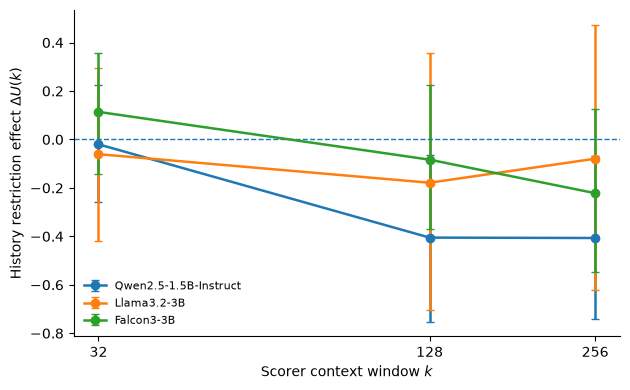

saved: ../figures/modern_generator_history_intervention.pdf
saved: ../figures/modern_generator_history_intervention.png


In [16]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))

order = [
    "Qwen2.5-1.5B-Instruct",
    "Llama3.2-3B",
    "Falcon3-3B",
]

for generator in order:
    z = headline[headline["generator"] == generator].sort_values("k")
    if len(z) == 0:
        continue

    y = z["mean"].to_numpy()
    err = np.vstack([
        y - z["ci_low"].to_numpy(),
        z["ci_high"].to_numpy() - y,
    ])

    ax.errorbar(
        z["k"],
        y,
        yerr=err,
        marker="o",
        linewidth=1.8,
        capsize=3,
        label=generator,
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xscale("log", base=2)
ax.set_xticks([32, 128, 256])
ax.set_xticklabels(["32", "128", "256"])
ax.set_xlabel("Scorer context window $k$")
ax.set_ylabel(r"History restriction effect $\Delta U(k)$")
ax.legend(frameon=False, fontsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

FIG_PDF = FIGURES / "modern_generator_history_intervention.pdf"
FIG_PNG = FIGURES / "modern_generator_history_intervention.png"

fig.savefig(FIG_PDF, bbox_inches="tight")
fig.savefig(FIG_PNG, dpi=250, bbox_inches="tight")
plt.show()

print("saved:", FIG_PDF)
print("saved:", FIG_PNG)


In [17]:
# ============================================================
# Falcon post-treatment eligibility audit
# ============================================================

falcon_scores = scores[
    (scores["generator"] == "Falcon3-3B")
    & (scores["scorer"] == "Qwen3-0.6B")
].copy()

falcon_gen = generations[
    generations["generator"] == "Falcon3-3B"
].copy()

gen_wide = (
    falcon_gen[
        [
            "source_id",
            "condition",
            "n_generator_tokens",
            "ended_eos",
        ]
    ]
    .pivot(
        index="source_id",
        columns="condition",
    )
)

gen_wide.columns = [
    f"{a}_{b}"
    for a, b in gen_wide.columns
]

gen_wide = gen_wide.reset_index()

audit = falcon_scores.merge(
    gen_wide,
    on="source_id",
    how="left",
)

print("=== ELIGIBILITY ===")
display(
    audit["eligible"]
    .value_counts()
    .rename("n")
    .to_frame()
)

print("\n=== GENERATION BEHAVIOR BY ELIGIBILITY ===")
display(
    audit.groupby("eligible").agg(
        n=("source_id", "size"),

        full_generator_tokens=(
            "n_generator_tokens_full",
            "mean",
        ),
        cap_generator_tokens=(
            "n_generator_tokens_cap32",
            "mean",
        ),

        full_eos_fraction=(
            "ended_eos_full",
            "mean",
        ),
        cap_eos_fraction=(
            "ended_eos_cap32",
            "mean",
        ),

        full_qwen_tokens=(
            "full_scorer_tokens_capped",
            "mean",
        ),
        cap_qwen_tokens=(
            "cap_scorer_tokens_capped",
            "mean",
        ),
    )
)

print("\n=== EXCLUDED PAIRS ===")
display(
    audit.loc[
        ~audit["eligible"],
        [
            "source_id",
            "full_scorer_tokens_capped",
            "cap_scorer_tokens_capped",
            "n_generator_tokens_full",
            "n_generator_tokens_cap32",
            "ended_eos_full",
            "ended_eos_cap32",
        ],
    ].sort_values(
        "full_scorer_tokens_capped"
    )
)

# How many pairs would satisfy shorter evaluation-prefix thresholds?
print("\n=== PAIRED LENGTH AVAILABILITY ===")

rows = []

for threshold in [288, 320, 352, 384]:
    okay = (
        (audit["full_scorer_tokens_capped"] >= threshold)
        &
        (audit["cap_scorer_tokens_capped"] >= threshold)
    )

    rows.append({
        "required_scorer_tokens": threshold,
        "eligible_pairs": int(okay.sum()),
        "fraction": float(okay.mean()),
    })

display(pd.DataFrame(rows))

=== ELIGIBILITY ===


,n
eligible,
True,44
False,16



=== GENERATION BEHAVIOR BY ELIGIBILITY ===


,n,full_generator_tokens,cap_generator_tokens,full_eos_fraction,cap_eos_fraction,full_qwen_tokens,cap_qwen_tokens
eligible,,,,,,,
False,16,230.562500,355.625,0.875000,0.375000,211.5625,293.75
True,44,466.795455,479.500,0.363636,0.022727,384.0000,384.00



=== EXCLUDED PAIRS ===


,source_id,full_scorer_tokens_capped,cap_scorer_tokens_capped,n_generator_tokens_full,n_generator_tokens_cap32,ended_eos_full,ended_eos_cap32
55,bc3b8481-b341-4e31-8425-872bf799c8eb,69,384,72,480,True,False
41,d2a76293-269e-4718-a953-2ddba91aaac0,85,71,88,73,True,True
40,2476797c-373f-49f2-9eca-c467688a266f,94,384,101,480,True,False
52,ea43e948-f368-444d-9213-089fef0133a7,103,384,107,480,True,False
13,183aba2c-8e9d-4170-8b8e-5f525566f24c,107,262,111,267,True,True
49,e3cccc1b-00e3-4042-aa26-093069760076,112,100,114,99,True,True
19,72946026-4d72-404d-b611-7d5f848be85c,114,384,120,480,True,False
43,01dc36f0-156c-440b-a7e0-e31b235c23ae,126,177,130,183,True,True
42,063d907a-f416-48b4-ab27-edbc9cdcf933,138,384,145,480,True,False
6,2ff0c19a-262e-4813-ad6b-b50b2d2f3d7d,280,384,298,480,True,False



=== PAIRED LENGTH AVAILABILITY ===


,required_scorer_tokens,eligible_pairs,fraction
0,288,48,0.800000
1,320,47,0.783333
2,352,46,0.766667
3,384,44,0.733333


In [18]:
falcon = scores[
    (scores["generator"] == "Falcon3-3B")
    & (scores["scorer"] == "Qwen3-0.6B")
].copy()

falcon = falcon.merge(
    prompts[["source_id", "domain"]],
    on="source_id",
    how="left",
)

print("=== ELIGIBILITY BY DOMAIN ===")
display(
    pd.crosstab(
        falcon["domain"],
        falcon["eligible"],
        margins=True,
    )
)

print("\n=== ELIGIBILITY FRACTION ===")
display(
    falcon.groupby("domain")["eligible"]
    .agg(["sum", "count", "mean"])
    .rename(
        columns={
            "sum": "eligible",
            "count": "total",
            "mean": "fraction",
        }
    )
)

print("\n=== EFFECTS WITHIN DOMAIN ===")

rows = []

for domain, z in falcon[falcon["eligible"]].groupby("domain"):
    for metric in [
        "delta_U_32",
        "delta_U_128",
        "delta_U_256",
        "delta_U_long",
        "selectivity_long_minus_short",
    ]:
        mean, lo, hi = bootstrap_mean_ci(
            z[metric].to_numpy()
        )

        rows.append({
            "domain": domain,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
        })

domain_effects = pd.DataFrame(rows)

display(
    domain_effects.sort_values(
        ["domain", "metric"]
    )
)

=== ELIGIBILITY BY DOMAIN ===


eligible,False,True,All
domain,,,
news,5,25,30
wiki,11,19,30
All,16,44,60



=== ELIGIBILITY FRACTION ===


,eligible,total,fraction
domain,,,
news,25,30,0.833333
wiki,19,30,0.633333



=== EFFECTS WITHIN DOMAIN ===


,domain,metric,n,mean,ci_low,ci_high
1,news,delta_U_128,25,0.018716,-0.430791,0.511528
2,news,delta_U_256,25,-0.112864,-0.649983,0.443954
0,news,delta_U_32,25,0.141200,-0.235592,0.525287
3,news,delta_U_long,25,-0.047074,-0.524324,0.467712
4,news,selectivity_long_minus_short,25,-0.188275,-0.489790,0.107638
6,wiki,delta_U_128,19,-0.217705,-0.535016,0.110831
7,wiki,delta_U_256,19,-0.365180,-0.693272,-0.013087
5,wiki,delta_U_32,19,0.077958,-0.212977,0.355201
8,wiki,delta_U_long,19,-0.291442,-0.600704,0.037838
9,wiki,selectivity_long_minus_short,19,-0.369400,-0.600905,-0.145029


In [19]:
qp = pd.read_parquet(
    Q_DIR / "confirmatory_pairs.parquet"
).copy()

# Verify schema first.
print(qp.columns.tolist())
display(qp.head())

# Existing paired effects.
# confirmatory_pairs uses delta_u32 / delta_u128 / delta_u256.
qp["delta_U_long"] = 0.5 * (
    qp["delta_u128"] + qp["delta_u256"]
)

qp["selectivity_long_minus_short"] = (
    qp["delta_U_long"] - qp["delta_u32"]
)

rows = []

for domain, z in qp.groupby("domain"):
    for metric in [
        "delta_u32",
        "delta_u128",
        "delta_u256",
        "delta_U_long",
        "selectivity_long_minus_short",
    ]:
        mean, lo, hi = bootstrap_mean_ci(
            z[metric].to_numpy()
        )

        rows.append({
            "domain": domain,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
        })

qwen_domain = pd.DataFrame(rows)

display(
    qwen_domain.sort_values(
        ["domain", "metric"]
    )
)

['source_id', 'domain', 'u32_cap', 'u128_cap', 'u256_cap', 'u32_full', 'u128_full', 'u256_full', 'delta_u32', 'delta_u128', 'delta_u256', 'scale_selectivity']


,source_id,domain,u32_cap,u128_cap,u256_cap,u32_full,u128_full,u256_full,delta_u32,delta_u128,delta_u256,scale_selectivity
0,1b2e45a9-88d5-4983-b735-dc521aa6c1dc,news,2.008917,2.224001,2.458952,1.615607,1.834161,1.784426,0.393310,0.389839,0.674525,0.281215
1,3b8f603e-fce8-4fb1-b5ef-49015b1e9677,news,0.302330,0.898695,0.802456,1.467537,1.519343,1.743952,-1.165207,-0.620648,-0.941496,-0.223711
2,4e7eee59-305e-4449-a385-516cd0eef09f,news,0.633965,0.336917,0.425314,1.300815,1.427285,1.966953,-0.666850,-1.090368,-1.541639,0.874789
3,fc13052b-289e-4247-9444-996c4d420c5d,news,1.335763,1.504388,1.574127,1.505178,2.619645,3.327440,-0.169416,-1.115257,-1.753313,1.583897
4,914cab2e-a79d-458d-b2c0-b173775dd0dd,news,0.509296,0.593017,0.795145,1.186303,1.459587,1.881858,-0.677007,-0.866569,-1.086712,0.409705


,domain,metric,n,mean,ci_low,ci_high
3,news,delta_U_long,30,-0.284037,-0.684654,0.130141
1,news,delta_u128,30,-0.310466,-0.730521,0.127324
2,news,delta_u256,30,-0.257609,-0.656762,0.152516
0,news,delta_u32,30,-0.050263,-0.368102,0.299889
4,news,selectivity_long_minus_short,30,-0.233775,-0.532227,0.050519
8,wiki,delta_U_long,30,-0.527894,-1.031895,-0.003564
6,wiki,delta_u128,30,-0.499799,-1.006259,0.018537
7,wiki,delta_u256,30,-0.555990,-1.067945,-0.024207
5,wiki,delta_u32,30,0.010416,-0.314951,0.364069
9,wiki,selectivity_long_minus_short,30,-0.538310,-0.936840,-0.141062


In [20]:
def bootstrap_group_difference(
    df,
    metric,
    group_col="domain",
    a="wiki",
    b="news",
    n_boot=10_000,
    seed=20260901,
):
    xa = df.loc[df[group_col] == a, metric].dropna().to_numpy()
    xb = df.loc[df[group_col] == b, metric].dropna().to_numpy()

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for i in range(n_boot):
        aa = xa[rng.integers(0, len(xa), len(xa))]
        bb = xb[rng.integers(0, len(xb), len(xb))]
        boot[i] = aa.mean() - bb.mean()

    estimate = xa.mean() - xb.mean()

    return {
        "estimate_wiki_minus_news": estimate,
        "ci_low": np.quantile(boot, 0.025),
        "ci_high": np.quantile(boot, 0.975),
    }


print("Qwen:")
print(
    bootstrap_group_difference(
        qp,
        "selectivity_long_minus_short"
    )
)

print("\nFalcon:")
print(
    bootstrap_group_difference(
        falcon[falcon["eligible"]],
        "selectivity_long_minus_short"
    )
)

Qwen:
{'estimate_wiki_minus_news': np.float32(-0.30453527), 'ci_low': np.float64(-0.8006806239485741), 'ci_high': np.float64(0.18171940706670284)}

Falcon:
{'estimate_wiki_minus_news': np.float64(-0.18112512782188225), 'ci_low': np.float64(-0.5526013369495918), 'ci_high': np.float64(0.20466180946697138)}


In [22]:
# ============================================================
# Llama eligibility + matched-prompt diagnostic
# ============================================================

# ------------------------------------------------------------
# 1. Get Llama IDs eligible under the frozen primary scorer.
# ------------------------------------------------------------

llama_primary = scores[
    (scores["generator"] == "Llama3.2-3B")
    & (scores["scorer"] == "Qwen3-0.6B")
].copy()

llama_ids = set(
    llama_primary.loc[
        llama_primary["eligible"],
        "source_id",
    ].astype(str)
)

print("Llama primary eligible IDs:", len(llama_ids))


# ------------------------------------------------------------
# 2. Basic eligibility / generation behavior audit.
# ------------------------------------------------------------

llama_gen = generations[
    generations["generator"] == "Llama3.2-3B"
].copy()

gen_wide = (
    llama_gen[
        [
            "source_id",
            "condition",
            "n_generator_tokens",
            "ended_eos",
        ]
    ]
    .pivot(
        index="source_id",
        columns="condition",
    )
)

gen_wide.columns = [
    f"{a}_{b}"
    for a, b in gen_wide.columns
]

gen_wide = gen_wide.reset_index()
gen_wide["source_id"] = gen_wide["source_id"].astype(str)

audit = llama_primary.merge(
    gen_wide,
    on="source_id",
    how="left",
)

audit = audit.merge(
    prompts[
        ["source_id", "domain"]
    ].assign(
        source_id=lambda x: x["source_id"].astype(str)
    ),
    on="source_id",
    how="left",
)

print("\n=== LLAMA ELIGIBILITY ===")
display(
    audit["eligible"]
    .value_counts()
    .rename("n")
    .to_frame()
)

print("\n=== BY DOMAIN ===")
display(
    audit.groupby("domain")["eligible"]
    .agg(["sum", "count", "mean"])
    .rename(
        columns={
            "sum": "eligible",
            "count": "total",
            "mean": "fraction",
        }
    )
)

print("\n=== GENERATION BEHAVIOR BY ELIGIBILITY ===")
display(
    audit.groupby("eligible").agg(
        n=("source_id", "size"),
        full_generator_tokens=(
            "n_generator_tokens_full",
            "mean",
        ),
        cap_generator_tokens=(
            "n_generator_tokens_cap32",
            "mean",
        ),
        full_eos_fraction=(
            "ended_eos_full",
            "mean",
        ),
        cap_eos_fraction=(
            "ended_eos_cap32",
            "mean",
        ),
        full_qwen_tokens=(
            "full_scorer_tokens_capped",
            "mean",
        ),
        cap_qwen_tokens=(
            "cap_scorer_tokens_capped",
            "mean",
        ),
    )
)

Llama primary eligible IDs: 28

=== LLAMA ELIGIBILITY ===


,n
eligible,
False,32
True,28



=== BY DOMAIN ===


,eligible,total,fraction
domain,,,
news,13,30,0.433333
wiki,15,30,0.500000



=== GENERATION BEHAVIOR BY ELIGIBILITY ===


,n,full_generator_tokens,cap_generator_tokens,full_eos_fraction,cap_eos_fraction,full_qwen_tokens,cap_qwen_tokens
eligible,,,,,,,
False,32,370.093750,330.3125,0.937500,0.468750,353.59375,279.3125
True,28,443.964286,476.7500,0.535714,0.071429,384.00000,384.0000


In [23]:
# ============================================================
# Qwen intervention restricted to the exact Llama-eligible IDs
# ============================================================

qp2 = qp.copy()
qp2["source_id"] = qp2["source_id"].astype(str)

q_same = qp2[
    qp2["source_id"].isin(llama_ids)
].copy()

q_same["delta_U_long"] = 0.5 * (
    q_same["delta_u128"]
    + q_same["delta_u256"]
)

q_same["selectivity_long_minus_short"] = (
    q_same["delta_U_long"]
    - q_same["delta_u32"]
)

print("Qwen pairs on Llama-eligible prompts:", len(q_same))

rows = []

for metric in [
    "delta_u32",
    "delta_u128",
    "delta_u256",
    "delta_U_long",
    "selectivity_long_minus_short",
]:
    mean, lo, hi = bootstrap_mean_ci(
        q_same[metric].to_numpy()
    )

    rows.append({
        "metric": metric,
        "n": len(q_same),
        "mean": mean,
        "ci_low": lo,
        "ci_high": hi,
    })

display(pd.DataFrame(rows))

Qwen pairs on Llama-eligible prompts: 28


,metric,n,mean,ci_low,ci_high
0,delta_u32,28,-0.215195,-0.486450,0.071613
1,delta_u128,28,-0.410067,-0.893887,0.093989
2,delta_u256,28,-0.526876,-1.039233,0.002301
3,delta_U_long,28,-0.468472,-0.959586,0.044843
4,selectivity_long_minus_short,28,-0.253277,-0.571744,0.061416


In [24]:
# ============================================================
# Direct paired Qwen-vs-Llama heterogeneity test
# on exactly the same 28 Llama-eligible prompts.
# ============================================================

# Llama, primary Qwen3-0.6B scorer
llama_same = scores[
    (scores["generator"] == "Llama3.2-3B")
    & (scores["scorer"] == "Qwen3-0.6B")
    & (scores["eligible"])
].copy()

llama_same["source_id"] = llama_same["source_id"].astype(str)

# Original Qwen intervention, same frozen scorer
q_same2 = qp.copy()
q_same2["source_id"] = q_same2["source_id"].astype(str)

q_same2 = q_same2[
    q_same2["source_id"].isin(llama_ids)
].copy()

q_same2["delta_U_long"] = 0.5 * (
    q_same2["delta_u128"]
    + q_same2["delta_u256"]
)

q_same2["selectivity_long_minus_short"] = (
    q_same2["delta_U_long"]
    - q_same2["delta_u32"]
)

# Merge by the pre-treatment RAID prompt identity.
paired = llama_same[
    [
        "source_id",
        "delta_U_32",
        "delta_U_128",
        "delta_U_256",
        "delta_U_long",
        "selectivity_long_minus_short",
    ]
].merge(
    q_same2[
        [
            "source_id",
            "delta_u32",
            "delta_u128",
            "delta_u256",
            "delta_U_long",
            "selectivity_long_minus_short",
        ]
    ],
    on="source_id",
    suffixes=("_llama", "_qwen"),
)

assert len(paired) == 28

# Normalize names for the first three coordinates.
paired["heterogeneity_U32"] = (
    paired["delta_U_32"]
    - paired["delta_u32"]
)

paired["heterogeneity_U128"] = (
    paired["delta_U_128"]
    - paired["delta_u128"]
)

paired["heterogeneity_U256"] = (
    paired["delta_U_256"]
    - paired["delta_u256"]
)

paired["heterogeneity_long"] = (
    paired["delta_U_long_llama"]
    - paired["delta_U_long_qwen"]
)

paired["heterogeneity_selectivity"] = (
    paired["selectivity_long_minus_short_llama"]
    - paired["selectivity_long_minus_short_qwen"]
)


def paired_bootstrap_ci(x, n_boot=10000, seed=20260901):
    x = np.asarray(x, dtype=float)

    rng = np.random.default_rng(seed)

    boot = np.empty(n_boot)

    for b in range(n_boot):
        idx = rng.integers(
            0,
            len(x),
            size=len(x),
        )
        boot[b] = x[idx].mean()

    return {
        "mean": x.mean(),
        "ci_low": np.quantile(boot, 0.025),
        "ci_high": np.quantile(boot, 0.975),
    }


rows = []

for metric in [
    "heterogeneity_U32",
    "heterogeneity_U128",
    "heterogeneity_U256",
    "heterogeneity_long",
    "heterogeneity_selectivity",
]:
    result = paired_bootstrap_ci(
        paired[metric].to_numpy()
    )

    rows.append({
        "metric": metric,
        "n": len(paired),
        **result,
    })

heterogeneity = pd.DataFrame(rows)

display(heterogeneity)

,metric,n,mean,ci_low,ci_high
0,heterogeneity_U32,28,0.154560,-0.308308,0.644645
1,heterogeneity_U128,28,0.231398,-0.559501,1.048644
2,heterogeneity_U256,28,0.447500,-0.339466,1.258881
3,heterogeneity_long,28,0.339449,-0.446179,1.150451
4,heterogeneity_selectivity,28,0.184889,-0.348271,0.764411


## 14. Save frozen analysis outputs


In [21]:
SUMMARY_PATH = RESULTS / "modern_generator_history_intervention_summary.csv"
CRITERION_PATH = RESULTS / "modern_generator_history_intervention_criterion.csv"
COMMON_PATH = RESULTS / "modern_generator_history_intervention_common_qwen_scorers.csv"
HEADLINE_PATH = RESULTS / "modern_generator_history_intervention_headline.csv"

summary.to_csv(SUMMARY_PATH, index=False)
criterion.to_csv(CRITERION_PATH, index=False)
common_summary.to_csv(COMMON_PATH, index=False)
headline.to_csv(HEADLINE_PATH, index=False)

print("saved:")
for p in [
    SCORE_PATH,
    SUMMARY_PATH,
    CRITERION_PATH,
    COMMON_PATH,
    HEADLINE_PATH,
    FIG_PDF,
    FIG_PNG,
]:
    print(" ", p)


saved:
  ../results/modern_generator_history_intervention_scores.parquet
  ../results/modern_generator_history_intervention_summary.csv
  ../results/modern_generator_history_intervention_criterion.csv
  ../results/modern_generator_history_intervention_common_qwen_scorers.csv
  ../results/modern_generator_history_intervention_headline.csv
  ../figures/modern_generator_history_intervention.pdf
  ../figures/modern_generator_history_intervention.png


## 15. Interpretation gate

### Both modern generators pass

The strongest safe generator-side claim becomes:

> **Restricting available generated self-history selectively suppresses
> long-range context utility across three generator families, including two
> contemporary 3B instruction models.**

If Qwen3-1.7B also resolves the same long-range/selectivity pattern, add that
the direction is stable under a larger scorer from the same observation family.

### One passes

> The causal history trace extends beyond the original sub-2B generators, but
> sensitivity is heterogeneous across contemporary generator families.

Do not discard the null generator.

### Neither passes but both are negative

> The modern-generator extension is directionally consistent but not
> sufficiently resolved under this sample size.

### Null or reverse-direction modern results

Then the generator-scale limitation is real. Further generator shopping should
stop unless motivated by a new independently specified hypothesis.

In every outcome, the intervention establishes

\[
\text{available self-history during generation}
\longrightarrow
U^{(q)}(k)
\]

for a frozen observation model \(q\); it does not recover source-model hidden
states or a unique latent dependency graph.
